---
numbering: false
---

# Download Landsat Data

In [26]:
import pystac_client
import planetary_computer
import odc.stac

import geopandas as gpd
import rioxarray as rxr
import numpy as np

import matplotlib.pyplot as plt

from shapely import box
from pystac import ItemCollection

## Use `pystac-client` to search for Landsat data

Set out our search criteria. If you cannot find a suitable image (e.g. your search returns zero items, or those that exist are cloudy) you may have to broaden your search criteria.

In [29]:
# Provide a name for our area of interest (AOI)
aoi_name = "bristol"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-2.76, 51.38,-2.43,51.53]

# Provide the date range for the search in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-06-01/2026-08-31"  # summer 2026

# Provide a cloud cover percentage threshold for filtering the search results
max_cloud_percent = 20  # maximum cloud cover percentage

# Filter only to scenes where fractional coverage of bounding box exceeds desired threshold
aoi_fraction_threshold = .7  # 70% minimum

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
# For example, "landsat-c2-l2" for Landsat Collection 2 Level 2 data.
# See https://planetarycomputer.microsoft.com/CATALOG for more examples
collection = "landsat-c2-l2"

Turn our bbox list into a `GeoPandas` dataframe to sanity check we have the correct region:

In [22]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

aoi.explore()

Connect the Microsoft Planetary Computer.

In [23]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

Search for the dataset according to our search parameters. I have included two custom `query` statements which you can comment/uncomment and edit if you like: 

 - Sorted by cloud cover in ascending order.
 - Search for only Landsats 5, 8, and 9 (ignoring 1-4, which are unimportant unless you are looking for pre-1990 data, and 7, which has scanline issues barring between 1999-2001).

In [25]:
# Search for cloud-free Landsat 8/9 Surface Reflectance (c2l2-sr) imagery in Summer
search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "eo:cloud_cover": {"lt": max_cloud_percent},  # Cloud cover less than 15%
        "platform": {"in": ["landsat-5", "landsat-8", "landsat-9"]},  # Return only Landsat 5, 8, and 9. 
        }, 
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]  # Sort by cloud cover in ascending order
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 6 matching scene(s).


The next cell is a custom script that filters out satellite scenes that only clip the area of interest by a small fraction. The minimum fraction you would like is set by `bbox_fraction_threshold` above (defaults to `0.7`, i.e. 70%).

In [32]:
# convert aoi to a geopandas dataframe
aoi_gdf = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

# convert search results to a geopandas dataframe
search_gdf = gpd.GeoDataFrame.from_features(items.to_dict(), crs="EPSG:4326")

# convert both to an equal area projection (EPSG:8857) so we can work in metres
aoi_gdf = aoi_gdf.to_crs(8857)
search_gdf = search_gdf.to_crs(8857)

# clip search gdf to aoi gdf
search_gdf = search_gdf.clip(aoi_gdf)

# Calculate the fraction of the AOI covered by each scene
search_gdf = search_gdf.sort_index()
search_gdf["frac"] = search_gdf.area / aoi_gdf.area.values[0]

# Include a boolean column indicating whether the scene exceeds the AOI fraction threshold
search_gdf["exceed_frac"] = np.where(search_gdf["frac"].values >= aoi_fraction_threshold, True, False)

# Reconstruct the ItemCollection with only the items that exceed the AOI fraction threshold
items_list = []
for i, exceed_frac in zip(items, search_gdf.exceed_frac.values):
    if exceed_frac == True:
        items_list.append(i)

items = ItemCollection(items=items_list)
print(f"Afer AOI filtering, returns {len(items)} Items")

Afer AOI filtering, returns 3 Items


If you cannot find any items after searching, you may have to broaden your search parameters.

## Downloading data with `odc-stac`

Select the first item (or edit the index number to select another if this one isn't suitable).

In [31]:
item = items[0]

date = item.properties['datetime'][:10]
epsg = item.properties['proj:code']
satellite = item.properties['platform']

print(f"Selected Scene ID: {item.id}")
print(f"Acquisition Date: {item.properties['datetime']}")
print(f"Cloud Cover: {item.properties['eo:cloud_cover']}%")
print(f"Projection: {item.properties['proj:code']}")

Selected Scene ID: LC09_L2SP_203024_20260711_02_T1
Acquisition Date: 2026-07-11T11:04:17.508127Z
Cloud Cover: 0.01%
Projection: EPSG:32630


Select the Landsat bands we want, and use `odc.stac.load()` to load our data. 

In [9]:
# Requested bands - I've commented out some we don't need for now, but you can uncomment them if you want to use them later
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    # 'swir16',  # band 6, shortwave infrared 1
    # 'swir22',  # band 7, shortwave infrared 2
]

# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    [item],
    bands=bands,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Uncomment if you want a different projection: by default, will use the native UTM zone CRS
    # resolution=100, # Uncomment if you want a different resolution: by default, will use the native resolution of the imagery
).squeeze()

# xarray is 'lazy' by default, meaning it doesn't (down)load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds.compute()

<xarray.Dataset> Size: 3MB
Dimensions:      (y: 561, x: 768)
Coordinates:
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-07-11T11:04:17.508127
Data variables:
    blue         (y, x) uint16 862kB 9134 9134 9129 9131 ... 9197 9200 9117 9335
    green        (y, x) uint16 862kB 10435 10461 10457 ... 10483 10168 10865
    red          (y, x) uint16 862kB 11119 11116 11132 ... 11154 10568 11699
    nir08        (y, x) uint16 862kB 9591 9592 9597 9616 ... 20110 19456 21249

Convert to a `band` dimension and add appropriate attribute names. Also, convert to fix `NaN` values and convert to surface refelctance.

In [10]:
# stack variables into a band dimension
ds = ds.to_array(dim="band").squeeze()

# add the band names as a long_name attribute to the dataset
ds.attrs["long_name"] = list(ds["band"].values)

# set zero to NaN
ds = ds.where(ds > 0)

# Surface reflectance scaling values
ds = ds * 0.0000275 - 0.2  # convert to SR

# Visualise
ds

<xarray.DataArray (band: 4, y: 561, x: 768)> Size: 7MB
array([[[0.051185  , 0.051185  , 0.05104749, ..., 0.043595  ,
         0.0639175 , 0.0574825 ],
        [0.05176251, 0.0512125 , 0.0511025 , ..., 0.0465375 ,
         0.05668499, 0.05200998],
        [0.05214749, 0.05126749, 0.0512125 , ..., 0.04752749,
         0.05404501, 0.0572625 ],
        ...,
        [0.0381225 , 0.04340249, 0.0364175 , ..., 0.0505525 ,
         0.04780249, 0.052505  ],
        [0.0369125 , 0.0419725 , 0.04062501, ..., 0.05211999,
         0.047775  , 0.05514501],
        [0.03611501, 0.0403225 , 0.0417525 , ..., 0.05299999,
         0.05071749, 0.05671249]],

       [[0.08696251, 0.08767749, 0.08756749, ..., 0.07013251,
         0.08940999, 0.08512001],
        [0.08751251, 0.08778749, 0.08795251, ..., 0.07370751,
         0.08506499, 0.07972999],
        [0.0883375 , 0.08764999, 0.0883375 , ..., 0.06776749,
         0.0757425 , 0.07731001],
...
        [0.07235999, 0.08960249, 0.06298248, ..., 0.09699999,
         0.0930125 , 0.10307749],
        [0.06991251, 0.08338751, 0.08171   , ..., 0.10360001,
         0.09119751, 0.113555  ],
        [0.06787749, 0.07832749, 0.08578001, ..., 0.10673501,
         0.09062   , 0.1217225 ]],

       [[0.06375249, 0.06377999, 0.0639175 , ..., 0.23549001,
         0.2070825 , 0.210575  ],
        [0.06598   , 0.06551249, 0.06576   , ..., 0.251935  ,
         0.23419751, 0.23312499],
        [0.06914251, 0.06796001, 0.06801499, ..., 0.24924   ,
         0.23505001, 0.194405  ],
        ...,
        [0.26365   , 0.2639525 , 0.3302275 , ..., 0.34032   ,
         0.33944   , 0.35764503],
        [0.2637325 , 0.2563625 , 0.279105  , ..., 0.34579253,
         0.33784503, 0.36870003],
        [0.25630748, 0.26131248, 0.28031498, ..., 0.35302502,
         0.33504003, 0.3843475 ]]], shape=(4, 561, 768), dtype=float32)
Coordinates:
  * band         (band) object 32B 'blue' 'green' 'red' 'nir08'
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-07-11T11:04:17.508127
Attributes:
    long_name:  ['blue', 'green', 'red', 'nir08']

Visualise to check the image has good coverage and quality. If it isn't appropriate, you can explore a different `item` above (e.g. `item = items[3]`).

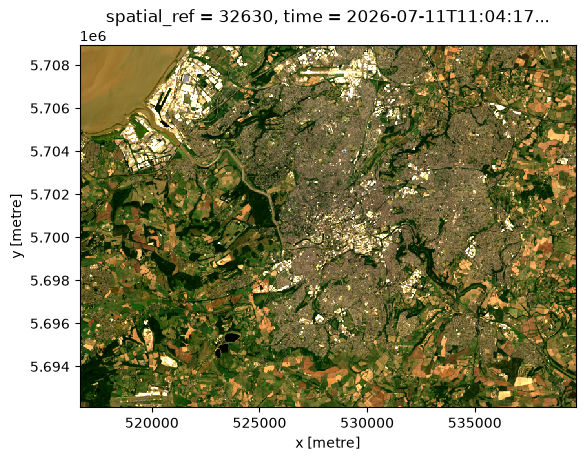

In [11]:
rgb = ds.sel(band=["red", "green", "blue"])

fig, ax = plt.subplots()
rgb.plot.imshow(ax=ax, robust=True)
ax.set_aspect("equal")

Save this under a sensible name, auto-generated from parameters:

In [13]:
filename = f"{aoi_name}_{date}_{satellite}.tif"

print('Saving to:', filename)

ds.rio.to_raster(filename, driver="GTiff", compress="deflate")

Saving to: bristol_2026-07-11_landsat-9.tif


An example of how to load the data:

In [14]:
ds_loaded = rxr.open_rasterio(filename, masked=True).squeeze()

ds_loaded['band'] = list(ds_loaded.attrs["long_name"])

ds_loaded

<xarray.DataArray (band: 4, y: 561, x: 768)> Size: 7MB
[1723392 values with dtype=float32]
Coordinates:
  * band         (band) <U5 80B 'blue' 'green' 'red' 'nir08'
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('blue', 'green', 'red', 'nir08')